**Retail_Sales_EDA**

**Step 1: Import Library**

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



**Step 2: Load Cleaned Dataset**

In [7]:
df = pd.read_csv("cleaned_superstore.csv")

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9800 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [15]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [17]:
df[["Order Date","Ship Date"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order Date  9800 non-null   datetime64[us]
 1   Ship Date   9800 non-null   datetime64[us]
dtypes: datetime64[us](2)
memory usage: 153.3 KB


**Step 3: Exploratory Data Analysis**

**1.Sales Distribution Analysis**

**Purpose:**  To understand the overall distribution of sales values and identify common transaction ranges, skewness, and potential outliers in the dataset.

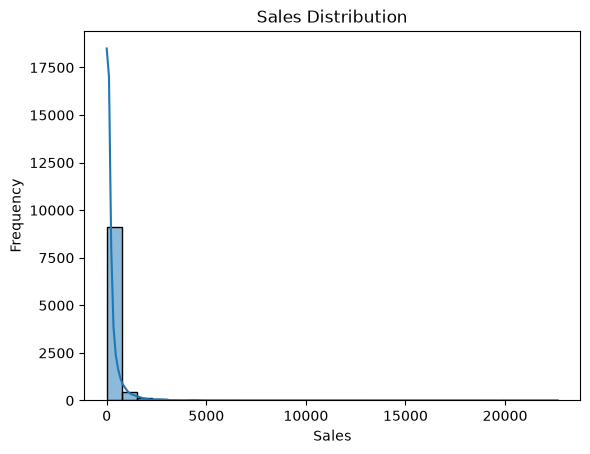

In [56]:
sns.histplot(
    df['Sales'],
    bins=30,
    kde=True
)

plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()

**Observation:**
Most sales transactions are concentrated at lower sales values, while a small number of transactions have very high sales amounts. This indicates a positively skewed (right-skewed) distribution with the presence of outliers.

**Business Insight:** A significant portion of sales comes from numerous small-value transactions, while a limited number of high-value orders contribute substantially to overall revenue.

**2.Category-wise Sales Analysis**

**Purpose:** To identify which product categories contribute the most to overall sales revenue.

In [59]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category_sales

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64

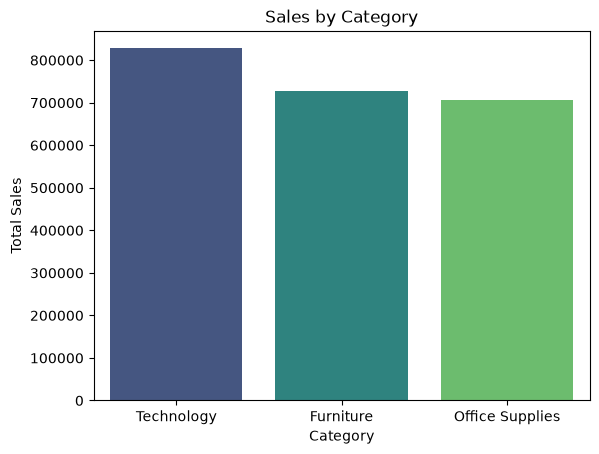

In [70]:
sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    hue=category_sales.index,
    palette='viridis',
    legend=False
)

plt.title('Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.show()

**Observation:**
Technology generated the highest sales revenue of 827,455.87, followed by Furniture with 728,658.58 and Office Supplies with 705,422.33. Although all three categories contributed significantly to overall sales, Technology emerged as the leading product category.

**Business Insight:**
Technology products are the primary revenue drivers for the business. Increasing inventory availability and promotional efforts for this category may further improve sales performance.

**Key Finding:**
Technology is the best-performing category in terms of sales revenue, contributing the highest share of total sales among all product categories.

**3.Sub-Category Wise Sales Analysis**

**Purpose:** To identify the best-performing and least-performing product sub-categories based on total sales revenue.

In [73]:
sub_category_sales=df.groupby("Sub-Category")['Sales'].sum().sort_values(ascending=False)
sub_category_sales

Sub-Category
Phones         327782.4480
Chairs         322822.7310
Storage        219343.3920
Tables         202810.6280
Binders        200028.7850
Machines       189238.6310
Accessories    164186.7000
Copiers        146248.0940
Bookcases      113813.1987
Appliances     104618.4030
Furnishings     89212.0180
Paper           76828.3040
Supplies        46420.3080
Art             26705.4100
Envelopes       16128.0460
Labels          12347.7260
Fasteners        3001.9600
Name: Sales, dtype: float64

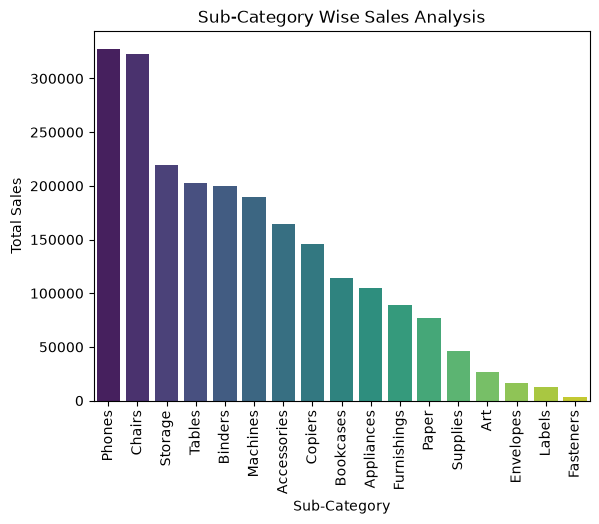

In [79]:
sns.barplot(
    x=sub_category_sales.index,
    y=sub_category_sales.values,
     hue=sub_category_sales.index,
    palette="viridis",
    legend=False
)

plt.title("Sub-Category Wise Sales Analysis")
plt.xlabel("Sub-Category")
plt.xticks(rotation=90)
plt.ylabel("Total Sales")

plt.show()

**Observation:**
Phones generated the highest sales revenue, followed by Chairs and Storage. On the other hand, Fasteners, Labels, and Envelopes contributed the least to overall sales. This indicates that sales revenue is heavily concentrated in a few high-performing sub-categories.
  
**Business Insight:**
    High-performing sub-categories such as Phones, Chairs, and Storage are key revenue drivers and should be prioritized for inventory planning and promotional activities. Low-performing sub-categories may require targeted marketing strategies or product portfolio evaluation to improve sales performance.

**Key Finding:**
Phones is the top-selling sub-category, while Fasteners is the lowest-performing sub-category in terms of sales revenue.

**4. Region-wise Sales Analysis**

**Purpose:** To analyze sales performance across different regions and identify the regions that contribute the most and least to overall revenue.

In [81]:
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

region_sales

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64

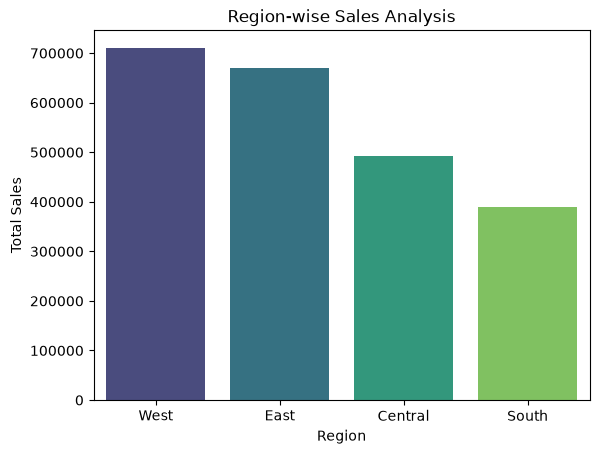

In [82]:
sns.barplot(
    x=region_sales.index,
    y=region_sales.values,
    hue=region_sales.index,
    palette='viridis',
    legend=False
)

plt.title('Region-wise Sales Analysis')
plt.xlabel('Region')
plt.ylabel('Total Sales')

plt.show()


**Observation:** The West region generated the highest sales revenue, followed closely by the East region. The Central region recorded moderate sales performance, while the South region contributed the lowest sales among all regions.

**Business Insight:** The West and East regions are the primary revenue-generating markets for the business and should continue to receive strategic focus. The South region presents an opportunity for growth through targeted marketing campaigns, customer acquisition strategies, and product promotion initiatives.

**Key Finding:** West is the top-performing region in terms of sales revenue, whereas South is the lowest-performing region.

**5.Segment-wise Sales Analysis:**

**Purpose:** To analyze sales performance across different customer segments and identify which customer group contributes the most to overall revenue.

In [85]:
segment_sales = df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)

segment_sales

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64

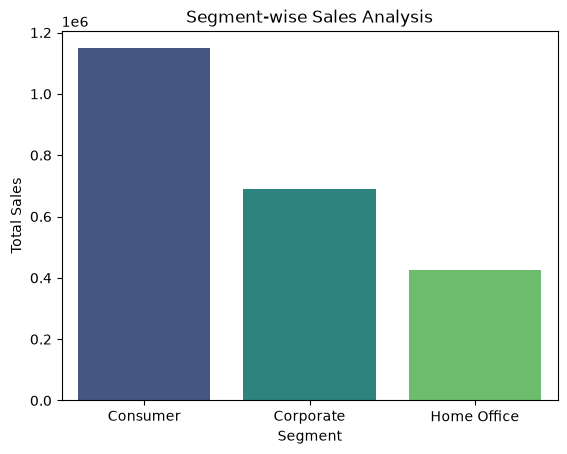

In [86]:
sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values,
    hue=segment_sales.index,
    palette='viridis',
    legend=False
)

plt.title('Segment-wise Sales Analysis')
plt.xlabel('Segment')
plt.ylabel('Total Sales')

plt.show()

**Observation:**
The Consumer segment generated the highest sales revenue, significantly outperforming the Corporate and Home Office segments. Corporate customers ranked second, while the Home Office segment contributed the lowest share of total sales.
  
**Business Insight:**
Consumer customers are the primary revenue drivers for the business. Focusing on customer retention programs, targeted promotions, and personalized marketing campaigns for this segment can help maximize revenue growth. Additionally, opportunities exist to increase sales from the Home Office segment through specialized offers and marketing initiatives.
  
**Key Finding:**
The Consumer segment is the highest-performing customer segment in terms of sales revenue, while the Home Office segment contributes the lowest sales.

**6.City-wise Sales Analysis**

**Purpose:** To analyze sales performance across different cities and identify the top revenue-generating locations for the business.

In [94]:
city_sales = df.groupby('City')['Sales'].sum().sort_values(ascending=False).head(10)

city_sales

City
New York City    252462.5470
Los Angeles      173420.1810
Seattle          116106.3220
San Francisco    109041.1200
Philadelphia     108841.7490
Houston           63956.1428
Chicago           47820.1330
San Diego         47521.0290
Jacksonville      44713.1830
Detroit           42446.9440
Name: Sales, dtype: float64

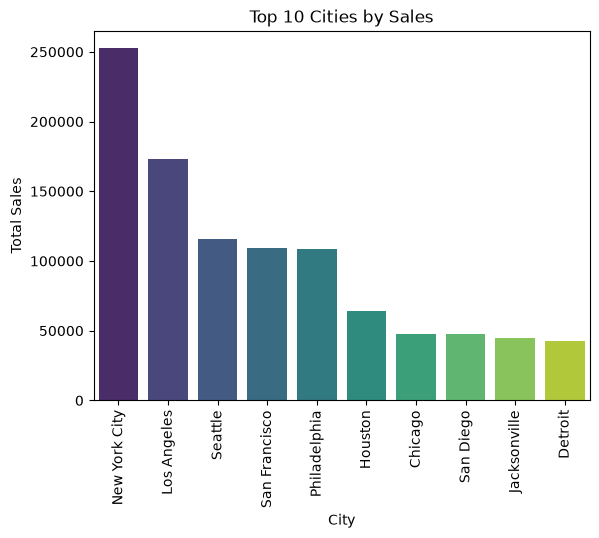

In [96]:
sns.barplot(
    x=city_sales.index,
    y=city_sales.values,
    hue=city_sales.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Cities by Sales')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)

plt.show()

**Observation:**
New York City generated the highest sales revenue, followed by Los Angeles and Seattle. San Francisco and Philadelphia also contributed significantly to overall sales. The remaining cities generated comparatively lower revenue.

**Business Insight:**
New York City and Los Angeles are major revenue-driving markets for the business. These cities present strong opportunities for customer retention, targeted promotions, and inventory optimization. Business strategies implemented in these high-performing cities can be replicated in lower-performing locations to improve overall sales performance.

**Key Finding:**
New York City is the highest-performing city in terms of sales revenue, while Detroit recorded the lowest sales among the top 10 cities analyzed.

**7.Monthly Sales Trend Analysis**

**Purpose:** To analyze monthly sales trends and identify seasonal patterns, peak-performing months, and periods with lower sales performance throughout the year.

In [91]:
df['Month'] = df['Order Date'].dt.month_name().sort_values(ascending=True)


month_order = [
    'January','February','March','April',
    'May','June','July','August',
    'September','October','November','December'
]

monthly_sales = df.groupby('Month')['Sales'].sum().reindex(month_order)


monthly_sales

Month
January       94291.6296
February      59371.1154
March        197573.5872
April        136283.0006
May          154086.7237
June         145837.5233
July         145535.6890
August       157315.9270
September    300103.4117
October      199496.2947
November     350161.7110
December     321480.1695
Name: Sales, dtype: float64

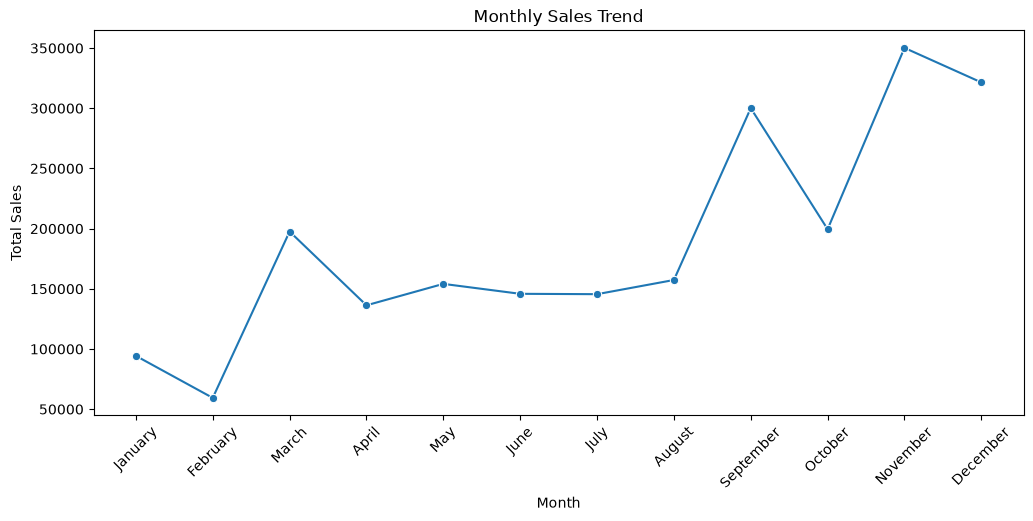

In [92]:
plt.figure(figsize=(12,5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.show()

**Observation:** Sales fluctuated throughout the year, with the highest sales recorded in November, followed by December and September. February generated the lowest sales revenue. A significant increase in sales was observed during the final quarter of the year.
  
**Business Insight:**
The business experiences stronger sales performance during the year-end months, particularly in November and December. This suggests that seasonal demand, holiday shopping, or promotional campaigns may significantly influence sales. Businesses can maximize revenue by increasing inventory levels and marketing efforts during these peak periods.


**Key Finding:**
November was the best-performing month in terms of sales revenue, while February recorded the lowest sales. The fourth quarter (September to December) showed the strongest sales performance overall.

**Advanced EDA**

**1.Multivariate Analysis**
**Purpose:**
To understand the relationship between multiple categorical variables and identify patterns in sales performance.

In [99]:
pivot_table = pd.pivot_table(
    df,
    values='Sales',
    index='Region',
    columns='Category',
    aggfunc='sum'
)

pivot_table

Category,Furniture,Office Supplies,Technology
Region,,,
Central,160317.4622,163590.243,168739.208
East,206461.3880,199940.811,263116.527
South,116531.4800,124424.771,148195.208
West,245348.2455,217466.509,247404.930


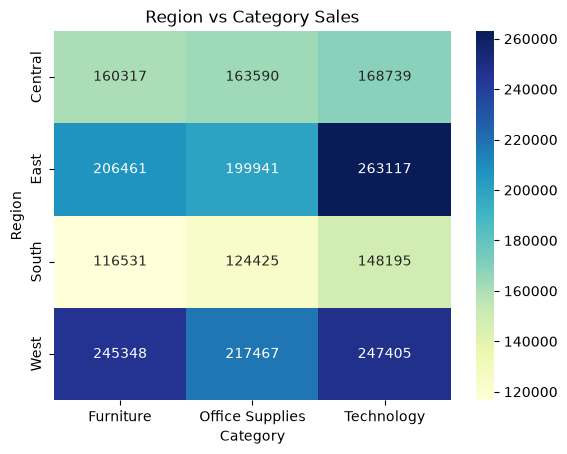

In [100]:
sns.heatmap(
    pivot_table,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Region vs Category Sales')

plt.show()

**Observation:**
Technology generated the highest sales in the East region (263,117), while Furniture and Technology performed strongly in the West region. Across all regions, Technology consistently recorded high sales compared to other categories.
  
**Business Insight:**
Technology products are strong revenue drivers across multiple regions, especially in the East and West. The business can focus on increasing stock availability and promotional efforts for Technology products in these regions to maximize revenue.

**Key Finding:**
Technology is the best-performing category across most regions, with the highest sales recorded in the East region.

**2.State-wise Sales Analysis:**

**Purpose:** To identify the highest and lowest revenue-generating states

In [120]:
state_sales_top5 = df.groupby(
    'State'
)['Sales'].sum().sort_values(
    ascending=False
).head(5)
state_sales_top5

State
California      446306.4635
New York        306361.1470
Texas           168572.5322
Washington      135206.8500
Pennsylvania    116276.6500
Name: Sales, dtype: float64

In [121]:
state_sales_last5 = df.groupby(
    'State'
)['Sales'].sum().sort_values(
    ascending=True
).head(5)
state_sales_last5

State
North Dakota      919.910
West Virginia    1209.824
Maine            1270.530
South Dakota     1315.560
Wyoming          1603.136
Name: Sales, dtype: float64

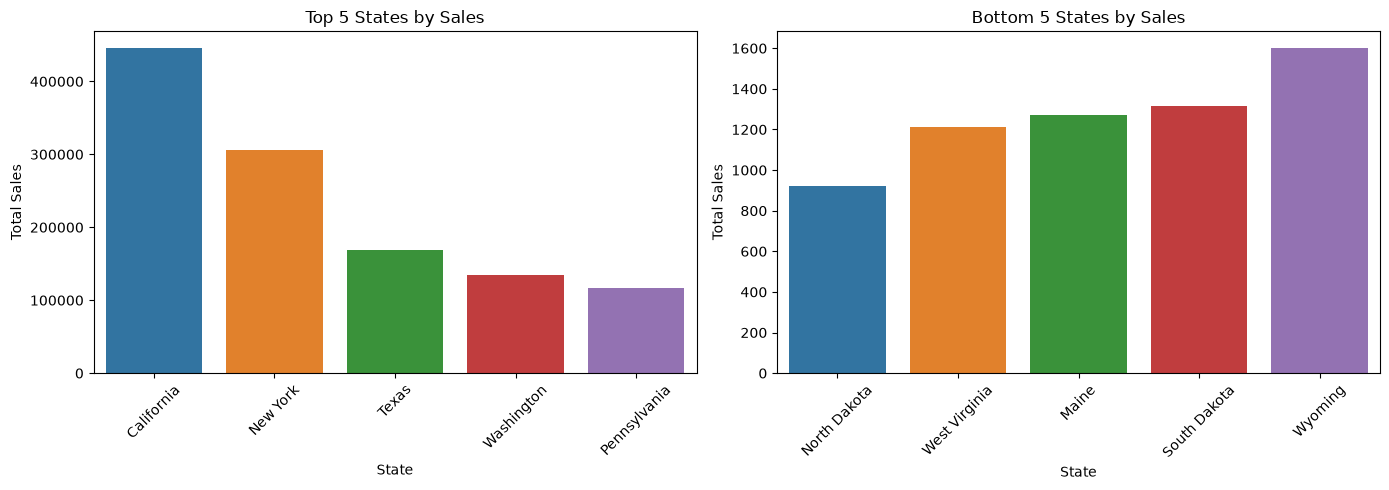

In [124]:
plt.figure(figsize=(14,5))
# Chart 1
plt.subplot(1,2,1)

sns.barplot(
    x=state_sales_top5.index,
    y=state_sales_top5.values,
    hue=state_sales_top5.index,
    legend=False
)

plt.title('Top 5 States by Sales')
plt.xticks(rotation=45)
plt.xlabel('State')
plt.ylabel('Total Sales')

# Chart 2
plt.subplot(1,2,2)

sns.barplot(
    x=state_sales_last5.index,
    y=state_sales_last5.values,
    hue=state_sales_last5.index,
    legend=False
)

plt.title('Bottom 5 States by Sales')
plt.xticks(rotation=45)
plt.xlabel('State')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

**Observation:**
California, New York, Texas, Washington, and Pennsylvania emerged as the top 5 revenue-generating states, with California significantly outperforming all others. In contrast, North Dakota, West Virginia, Maine, South Dakota, and Wyoming recorded the lowest sales revenue, contributing only a small share of the overall sales.

**Business Insight:**
The business has a strong market presence in states such as California and New York, making them key revenue drivers. Meanwhile, the bottom-performing states represent potential growth opportunities where targeted marketing campaigns, customer acquisition strategies, and regional promotions could help improve sales performance.

**Key Finding:**
California is the highest-performing state in terms of sales revenue, whereas North Dakota is the lowest-performing state. There is a substantial sales gap between the top-performing and bottom-performing states, highlighting significant differences in regional market performance.

**3.Customer Segment vs Category**

**Purpose:** To understand product category preferences across different customer segments.

In [107]:
segment_category = pd.crosstab(
    df['Segment'],
    df['Category']
)

segment_category

Category,Furniture,Office Supplies,Technology
Segment,,,
Consumer,1093,3072,936
Corporate,628,1783,542
Home Office,357,1054,335


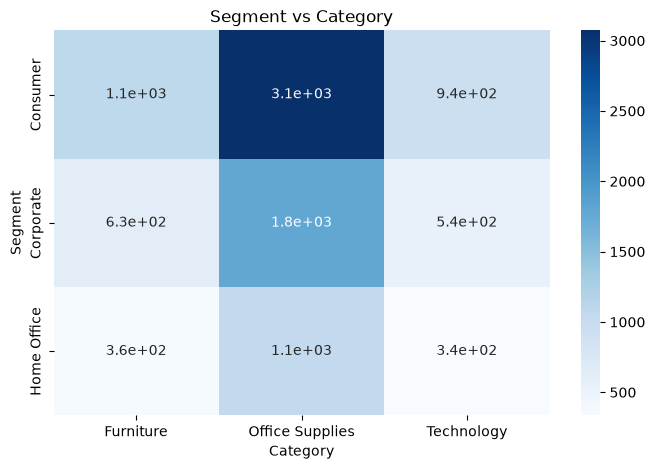

In [108]:
plt.figure(figsize=(8,5))

sns.heatmap(
    segment_category,
    annot=True,
    cmap='Blues'
)

plt.title('Segment vs Category')

plt.show()

**Observation:** Office Supplies recorded the highest number of transactions across all customer segments. The Consumer segment showed the highest purchasing activity, followed by Corporate and Home Office segments.
  
**Business Insight:**
Consumer customers contribute the majority of purchases across all categories. Marketing campaigns and customer retention strategies focused on Consumer customers can further improve sales performance.

**Key Finding:**
The Consumer segment is the most active customer segment, with Office Supplies being the most frequently purchased category.

**4.Day-wise Sales Analysis**

**Purpose:**
To analyze sales performance across different days of the week and identify peak and low sales days for better operational and marketing planning.

In [115]:
df['Day Name'] = df['Order Date'].dt.day_name()

In [116]:
day_sales = df.groupby(
    'Day Name'
)['Sales'].sum()

day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

day_sales = day_sales.reindex(day_order)
day_sales

Day Name
Monday       348791.5516
Tuesday      420535.9243
Wednesday    315888.9722
Thursday     142839.2402
Friday       234710.8402
Saturday     420901.4763
Sunday       377868.7779
Name: Sales, dtype: float64

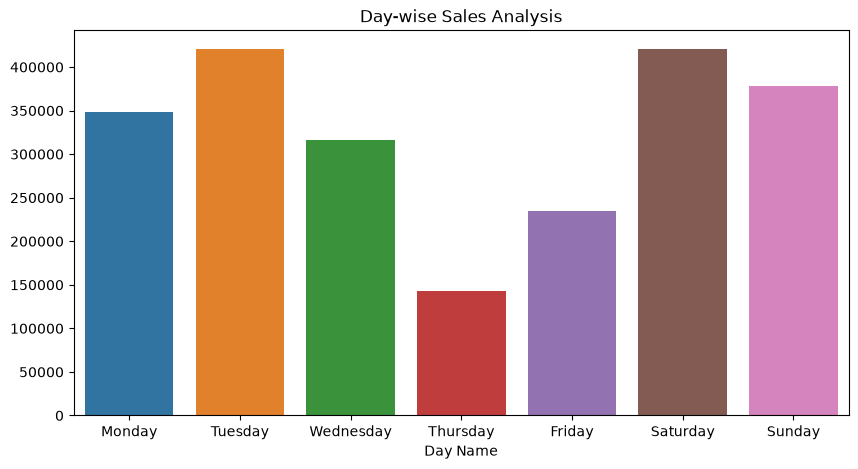

In [117]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=day_sales.index,
    y=day_sales.values,
    hue=day_sales.index,
    legend=False
)

plt.title('Day-wise Sales Analysis')

plt.show()

**Observation:**
Sales performance varied across the week, with Tuesday and Saturday generating the highest sales revenue. Sunday and Monday also recorded strong sales, while Thursday produced the lowest sales among all days.

**Business Insight:**
Customer purchasing activity is higher during weekends and early weekdays. Businesses can maximize revenue by launching promotions, stocking high-demand products, and scheduling marketing campaigns on high-performing days such as Tuesday and Saturday.

**Key Finding:**
Tuesday and Saturday are the best-performing sales days, whereas Thursday records the lowest sales revenue.

**Step 4: Business Insights**

1.Technology is the highest revenue-generating product category and serves as a key business revenue driver.

2.Phones, Chairs, and Storage are the top-performing sub-categories, contributing significantly to overall sales.

3.The West and East regions generate the highest sales revenue, while the South region has comparatively lower sales performance.

4.California and New York are the strongest markets, whereas states such as North Dakota and Wyoming represent potential growth opportunities.

5.Consumer customers contribute the largest share of sales compared to Corporate and Home Office segments.

6.Sales peak during November and December, indicating strong seasonal demand during the year-end period.

7.Tuesday and Saturday generate the highest sales revenue, making them ideal days for promotional campaigns and marketing activities.

8.New York City and Los Angeles are the highest-performing cities and play a significant role in overall business growth.

**Step 5: Conculsion:**

This project analyzed retail sales data to uncover key business insights and sales trends. Technology was identified as the highest revenue-generating category, while California and New York emerged as the top-performing markets. The Consumer segment contributed the highest sales, and strong seasonal patterns were observed during November and December. The findings can help businesses optimize inventory, improve marketing strategies, and drive revenue growth through data-driven decision-making.